## Homework 1. Introduction to PyTorch

<font color='OrangeRed'>**Note!**</font> This assignment requires access to a GPU. We suggest doing it in Google Colab. If you want to and have a GPU at home, you can install the drivers and libraries needed to work with your GPU and do the assignment locally.

<font color='OrangeRed'>**Note!**</font> When working in Google Colab, make sure you have selected the T4 runtime. You can enable it in the menu shown in the pictures below:

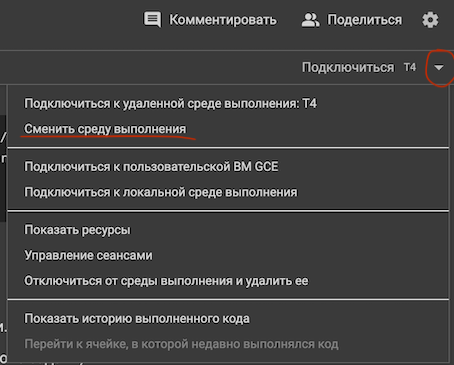

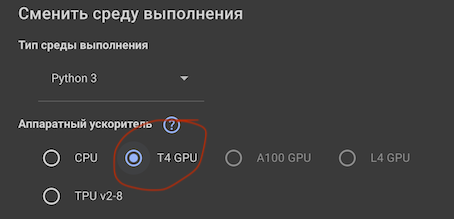

<font color='OrangeRed'>**Note!**</font> Since the T4 runtime is free, Google Colab limits its use after some session time. Run computations on the GPU only once you have made sure that the same code works on the CPU! As a last resort, you can create several Google accounts if this happens.

# Assignment

<font color='OrangeRed'>**Important!**</font> Unless stated otherwise, all data must be created and processed on the CPU

##  **Task 1 [3 points]**

Create a 10$\times$10 tensor (matrix) filled with random numbers from the standard normal distribution.

In [ ]:
import torch
torch.manual_seed(0)

X = torch.randn(10, 10)
print(X.mean()) # 0
print(X.std())  # 1
X

tensor(0.0371)
tensor(1.0296)


tensor([[-1.1258e+00, -1.1524e+00, -2.5058e-01, -4.3388e-01,  8.4871e-01,
          6.9201e-01, -3.1601e-01, -2.1152e+00,  3.2227e-01, -1.2633e+00],
        [ 3.4998e-01,  3.0813e-01,  1.1984e-01,  1.2377e+00,  1.1168e+00,
         -2.4728e-01, -1.3527e+00, -1.6959e+00,  5.6665e-01,  7.9351e-01],
        [ 5.9884e-01, -1.5551e+00, -3.4136e-01,  1.8530e+00,  7.5019e-01,
         -5.8550e-01, -1.7340e-01,  1.8348e-01,  1.3894e+00,  1.5863e+00],
        [ 9.4630e-01, -8.4368e-01, -6.1358e-01,  3.1593e-02, -4.9268e-01,
          2.4841e-01,  4.3970e-01,  1.1241e-01,  6.4079e-01,  4.4116e-01],
        [-1.0231e-01,  7.9244e-01, -2.8967e-01,  5.2507e-02,  5.2286e-01,
          2.3022e+00, -1.4689e+00, -1.5867e+00, -6.7309e-01,  8.7283e-01],
        [ 1.0554e+00,  1.7784e-01, -2.3034e-01, -3.9175e-01,  5.4329e-01,
         -3.9516e-01, -4.4622e-01,  7.4402e-01,  1.5210e+00,  3.4105e+00],
        [-1.5312e+00, -1.2341e+00,  1.8197e+00, -5.5153e-01, -5.6925e-01,
          9.1997e-01,  1.1108e+0



Write a function that computes the trace of a matrix using torch. BUT you may not use the built-in `torch.trace` method.

Feel free to google the methods you need

In [ ]:
def trace(X):
    dim = X.dim()
    if dim != 2:
        print("expected a matrix, but got tensor with dim " + str(dim))
    trace = torch.sum(torch.diagonal(X))
    return trace

In [ ]:
LOL = torch.ones(4, 4)
trace(LOL)

tensor(4.)

In [ ]:
assert torch.abs(trace(X) - torch.trace(X)) < 1e-6, 'Ошибка в вычисление следа матрицы'
print('Отлично!')

Отлично!




We know that trigonometric functions can also be applied to matrices. To find $sin(X)$, where $X \in \mathbb{R}^{n\times n}$ is a matrix with $n$ rows and $n$ columns, recall the Taylor series expansion of the sine:

$sin(x) = x - \frac{x^3}{3!} + \frac{x^5}{5!} - \frac{x^7}{7!}+\dots$

and substitute the matrix $X$ for $x$:

$sin(X) = X - \frac{X^3}{3!} + \frac{X^5}{5!} - \frac{X^7}{7!}+\dots$

Then $sin(X)$ is also a matrix!

Your task is to write a function that computes $sin(X)$ using the Taylor expansion. We stop at the 15th power, i.e.:
$sin(X) \approx X - \frac{X^3}{3!} + \frac{X^5}{5!} - \frac{X^7}{7!}+ \dots - \frac{X^{15}}{15!}$

In [ ]:
LOL = torch.ones(4, 4) * 3
print(LOL ** 3)
print(LOL ** 3 / math.factorial(3))

tensor([[27., 27., 27., 27.],
        [27., 27., 27., 27.],
        [27., 27., 27., 27.],
        [27., 27., 27., 27.]])
tensor([[4.5000, 4.5000, 4.5000, 4.5000],
        [4.5000, 4.5000, 4.5000, 4.5000],
        [4.5000, 4.5000, 4.5000, 4.5000],
        [4.5000, 4.5000, 4.5000, 4.5000]])


In [ ]:
import math

def sin(X):
    result = X
    pre_elem = X ** 3
    sign = -1
    for i in range(2, 16):
        if ((i % 2) == 1):
            #print(i)
            #print(str(sign) + " (" + str(pre_elem) + " / " + str(math.factorial(i)) + ")")
            exp = sign * ((X ** i) / math.factorial(i))
            #print(exp)
            result += exp
            sign *= -1
    return result
def math_sin(X):
    return [[math.sin(element) for element in row] for row in X]

In [ ]:
LOL = torch.ones(4, 4) * math.pi / 6
print(math.pi / 6 - (math.pi / 6) ** 3 / 6 + (math.pi / 6) ** 5 / 120 - (math.pi / 6) ** 7 / (120 * 6 * 7) + (math.pi / 6) ** 9 / (120 * 6 * 7 * 8 * 9))
print(sin(LOL))
print(math_sin(LOL))
torch.sin(LOL)

0.5000000000202799
tensor([[0.4999, 0.4999, 0.4999, 0.4999],
        [0.4999, 0.4999, 0.4999, 0.4999],
        [0.4999, 0.4999, 0.4999, 0.4999],
        [0.4999, 0.4999, 0.4999, 0.4999]])
[[0.47936606331085385, 0.47936606331085385, 0.47936606331085385, 0.47936606331085385], [0.47936606331085385, 0.47936606331085385, 0.47936606331085385, 0.47936606331085385], [0.47936606331085385, 0.47936606331085385, 0.47936606331085385, 0.47936606331085385], [0.47936606331085385, 0.47936606331085385, 0.47936606331085385, 0.47936606331085385]]


tensor([[0.4794, 0.4794, 0.4794, 0.4794],
        [0.4794, 0.4794, 0.4794, 0.4794],
        [0.4794, 0.4794, 0.4794, 0.4794],
        [0.4794, 0.4794, 0.4794, 0.4794]])

WTF 😭😭😭 what do you do when the torch function is broken — it is off by literally 0.02 when computing sin(π÷6)

In [ ]:
x = torch.eye(100) * torch.pi / 2
print(sin(X))
print(torch.sin(X))
assert torch.abs(torch.sin(x) - sin(x)).sum() < 1e-5, 'Ошибка в вычислении синуса'

print('Отлично!')

tensor([[-0.7763, -0.7821, -0.2454, -0.4081,  0.6800,  0.5950, -0.3058, -0.5126,
          0.3115, -0.8002],
        [ 0.3362,  0.2986,  0.1193,  0.7969,  0.7742, -0.2423, -0.8078, -0.7731,
          0.5112,  0.6526],
        [ 0.5341, -0.8008, -0.3285,  0.7129,  0.6292, -0.5247, -0.1717,  0.1814,
          0.8090,  0.7965],
        [ 0.7216, -0.6776, -0.5442,  0.0316, -0.4555,  0.2434,  0.4129,  0.1119,
          0.5625,  0.4141],
        [-0.1020,  0.6521, -0.2818,  0.0525,  0.4788,  0.2653, -0.8081, -0.7964,
         -0.5833,  0.6910],
        [ 0.7581,  0.1760, -0.2263, -0.3726,  0.4941, -0.3755, -0.4182,  0.6257,
          0.8045,     nan],
        [-0.8035, -0.7964,  0.7287, -0.5002, -0.5131,  0.7112,  0.7728,  0.8031,
         -0.8076, -0.2501],
        [-0.4400,  0.3234, -0.7889, -0.4989, -0.4453, -0.4609, -0.7614,  0.7738,
         -0.1397,  0.6589],
        [-0.0931,  0.5920, -0.6750,  0.0009,  0.3535, -0.7730, -0.2243,  0.2728,
          0.0731,  0.7734],
        [ 0.2749,  

AssertionError: Ошибка в вычислении синуса

##  **Task 2 [2 points]**

PyTorch lets you move computations to other devices, such as a graphics card. Moving computations from the CPU to the GPU when training neural networks has several key advantages that come from the GPU architecture and the requirements of neural-network computations:

1. **Parallel data processing**:
    * **GPUs** are designed for parallel computing and can process thousands of threads at once, which is ideal for operations such as matrix multiplications and convolutions.
    * **CPUs**, in contrast, are optimized for sequential operations and have a limited number of cores (usually 4–16). Although a CPU can handle parallel workloads, it is not as efficient for tasks that require massive parallelism.
2. **High memory bandwidth**:
    * **GPUs** have higher memory bandwidth, which lets them move large amounts of data faster.
3. **Optimization for vector and matrix operations**:
    * Unlike **CPUs**, **GPUs** are specifically optimized for vector operations (matrix multiplication, vector addition, etc.) thanks to an architecture with many cores and instructions optimized for linear algebra.
4. **Efficient tensor operations**:
    * Neural networks rely heavily on tensor computations, and **GPUs** are designed to handle tensor operations efficiently. For example, modern NVIDIA **GPUs** use Tensor Cores, a technology built specifically to accelerate tensor operations, which significantly speeds up training of deep models.

<font color='LightSteelBlue'>**Hint**</font>

In code, you can move data from one device to another with the `to` method (of the data or the model), or by specifying the memory directly with a method:

```
device = torch.device("cuda")
X = X.to(device)
X = X.cpu()
```



Create three random matrices $X$, $Y$ and $Z$ of size $10000 \times 10000$ on the **CPU** device.

Use the `%%time` magic command to measure the execution time of the following operations:

* $R_1 = X + Y + Z$,
* $R_2 = X \otimes Y \otimes Z$, where $\otimes$ is ordinary matrix multiplication.

In [ ]:
import torch
n = 10000
X = torch.rand(n, n)
Y = torch.rand(n, n)
Z = torch.rand(n, n)

In [ ]:
%%time

R1 = X + Y + Z

CPU times: user 205 ms, sys: 719 ms, total: 925 ms
Wall time: 926 ms


In [ ]:
%%time

R2 = X * Y * Z

CPU times: user 194 ms, sys: 1.25 s, total: 1.45 s
Wall time: 1.47 s





 Now move $X$, $Y$, $Z$ to the **GPU** and measure how fast the operations run on the graphics card. Write down what you noticed

In [ ]:
X = X.cuda()
Y = Y.cuda()
Z = Z.cuda()

In [ ]:
%%time

R1 = X + Y + Z

CPU times: user 7.7 ms, sys: 12.1 ms, total: 19.8 ms
Wall time: 46.9 ms


In [ ]:
%%time

R2 = X * Y * Z

CPU times: user 4.75 ms, sys: 4.84 ms, total: 9.6 ms
Wall time: 31.9 ms


<font color='MediumOrchid'>**Your conclusions:**</font> This is insane: matrix addition and multiplication run many times faster on the GPU than on the CPU <br>
cpu & addition: 926 ms <br>
cpu & multiplication: 1.47 s <br>
gpu & addition: 46.9 ms <br>
gpu & multiplication: 31.9 ms

## **Task 3 [5 points]**

Let's make the previous task a bit harder.

Neural networks contain many layers, activation functions and regularizations. Imagine we work at a bank and are building a neural network that classifies transactions as normal or fraudulent. One transaction is a feature vector of **1024** values. Millions of transactions happen every second.

Your task is to assemble (not train) a neural network of **three linear layers** and **three activation functions**, one after each linear layer, according to the following diagram:

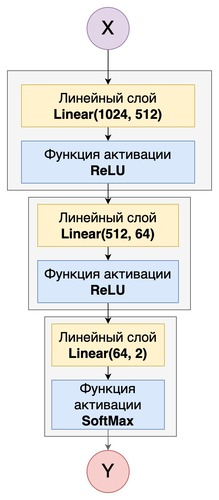



Create a random input matrix $X \in \mathbb{R}^{1000000 \times 1024}$ — 1 million transactions combined into one matrix. The distribution is standard normal

In [ ]:
import torch
X = torch.rand(1000000, 1024)



Create **three linear layers** with `torch.nn.Linear`. The first takes 1024 features and outputs 512. The second takes 512 and outputs 64. The third takes 64 features and outputs 2 — the model's scores for the transaction being normal and fraudulent.

More about the layer: https://pytorch.org/docs/stable/generated/torch.nn.Linear.html

Also define two activation functions: **ReLU** and **SoftMax**. More details:
https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html
https://pytorch.org/docs/stable/generated/torch.nn.Softmax.html

In [ ]:
from torch import nn


linear1 = nn.Linear(1024, 512)
linear2 = nn.Linear(512, 64)
linear3 = nn.Linear(64, 2)

relu1 = nn.ReLU()
relu2 = nn.ReLU()
softmax = nn.Softmax()



Write a function that applies this network to the given input data, moving the data and the model to a specified device.

In [ ]:
from torch import nn

def infer(X, device='cpu'):
    """
    Применяет описанные выше слои к данным X
    Перекладывает данные и модель на конкретный device
    device: 'cpu' or 'cuda'

    Return
    y, выход, который получается после применения нейросети над данными X
    """
    device = torch.device(device)

    X = X.to(device)

    linear1 = nn.Linear(1024, 512).to(device)
    linear2 = nn.Linear(512, 64).to(device)
    linear3 = nn.Linear(64, 2).to(device)

    relu1 = nn.ReLU().to(device)
    relu2 = nn.ReLU().to(device)
    softmax = nn.Softmax(dim=1).to(device)

    l1 = linear1(X)
    r1 = relu1(l1)
    l2 = linear2(r1)
    r2 = relu2(l2)
    l3 = linear3(r2)
    s1 = softmax(l3)


    return s1

Using this function, pass the data `X` through the network and measure the execution time:

In [ ]:
%%time

Y = infer(X)

assert Y.shape[0] == 1000000 and Y.shape[1] == 2, 'Ошибка в model, несоответствие размеров выходных данных'
assert Y.device == torch.device("cpu"), "Выходные данные лежат не на CPU"
print('Отлично!')

Отлично!
CPU times: user 17.4 s, sys: 2.96 s, total: 20.4 s
Wall time: 20.8 s




Now move the input data $X$ and the network to the graphics card and find out how much faster the computation is.

In your conclusions, describe how much faster the computation was on the GPU compared with the CPU.

<font color='OrangeRed'>**Warning!**</font> In this task the GPU memory may overflow in Google Colab after several incorrect runs. In that case we recommend "disconnecting and deleting the runtime" and redoing the computations for this step (there is no need to rerun the previous steps)

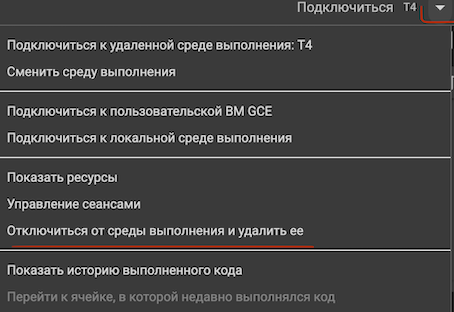

In [ ]:
%%time
X = X.cuda()
Y = infer(X, device="cuda")

assert Y.shape[0] == 1000000 and Y.shape[1] == 2, 'Ошибка в model, несоответствие размеров выходных данных'
assert Y.device != torch.device("cpu"), "Выходные данные лежат не на GPU"
print('Отлично!')

Отлично!
CPU times: user 1.33 s, sys: 623 ms, total: 1.96 s
Wall time: 2.21 s


**Your conclusions:**

**Task [1 point]:**

Answer the questions:
- what is the main advantage of a **GPU** over a **CPU**?
- in which cases is a **CPU** used instead of a **GPU**?
- what is the main characteristic of graphics cards to look at when training neural networks?
- why is `SoftMax` the last element of the network?
- why are activation functions placed between the linear layers?

If needed, use the lecture and seminar materials; you can also google and study relevant information

**Your conclusions:**
The function ran in 2.21 s on the GPU and 20.8 s on the CPU — literally a 10× difference <br>
Graphics cards have several thousand cores, so the GPU is much faster at parallel operations, such as matrix operations — really much faster.<br>
CPUs are used for sequential tasks with few parallel operations <br>
I think people look at the number of cores and how well they are optimized for vector and matrix operations, but many sources also say to choose by the amount of GPU memory for more complex models <br>
SoftMax is the last element so that the output is a valid probability distribution: the probability that a transaction is fraudulent and the probability that it is normal. <br>
If we do not use activation functions, then

1.   a single linear layer would be enough
2.   it would just be a not very smart model that cannot pick up anything meaningful